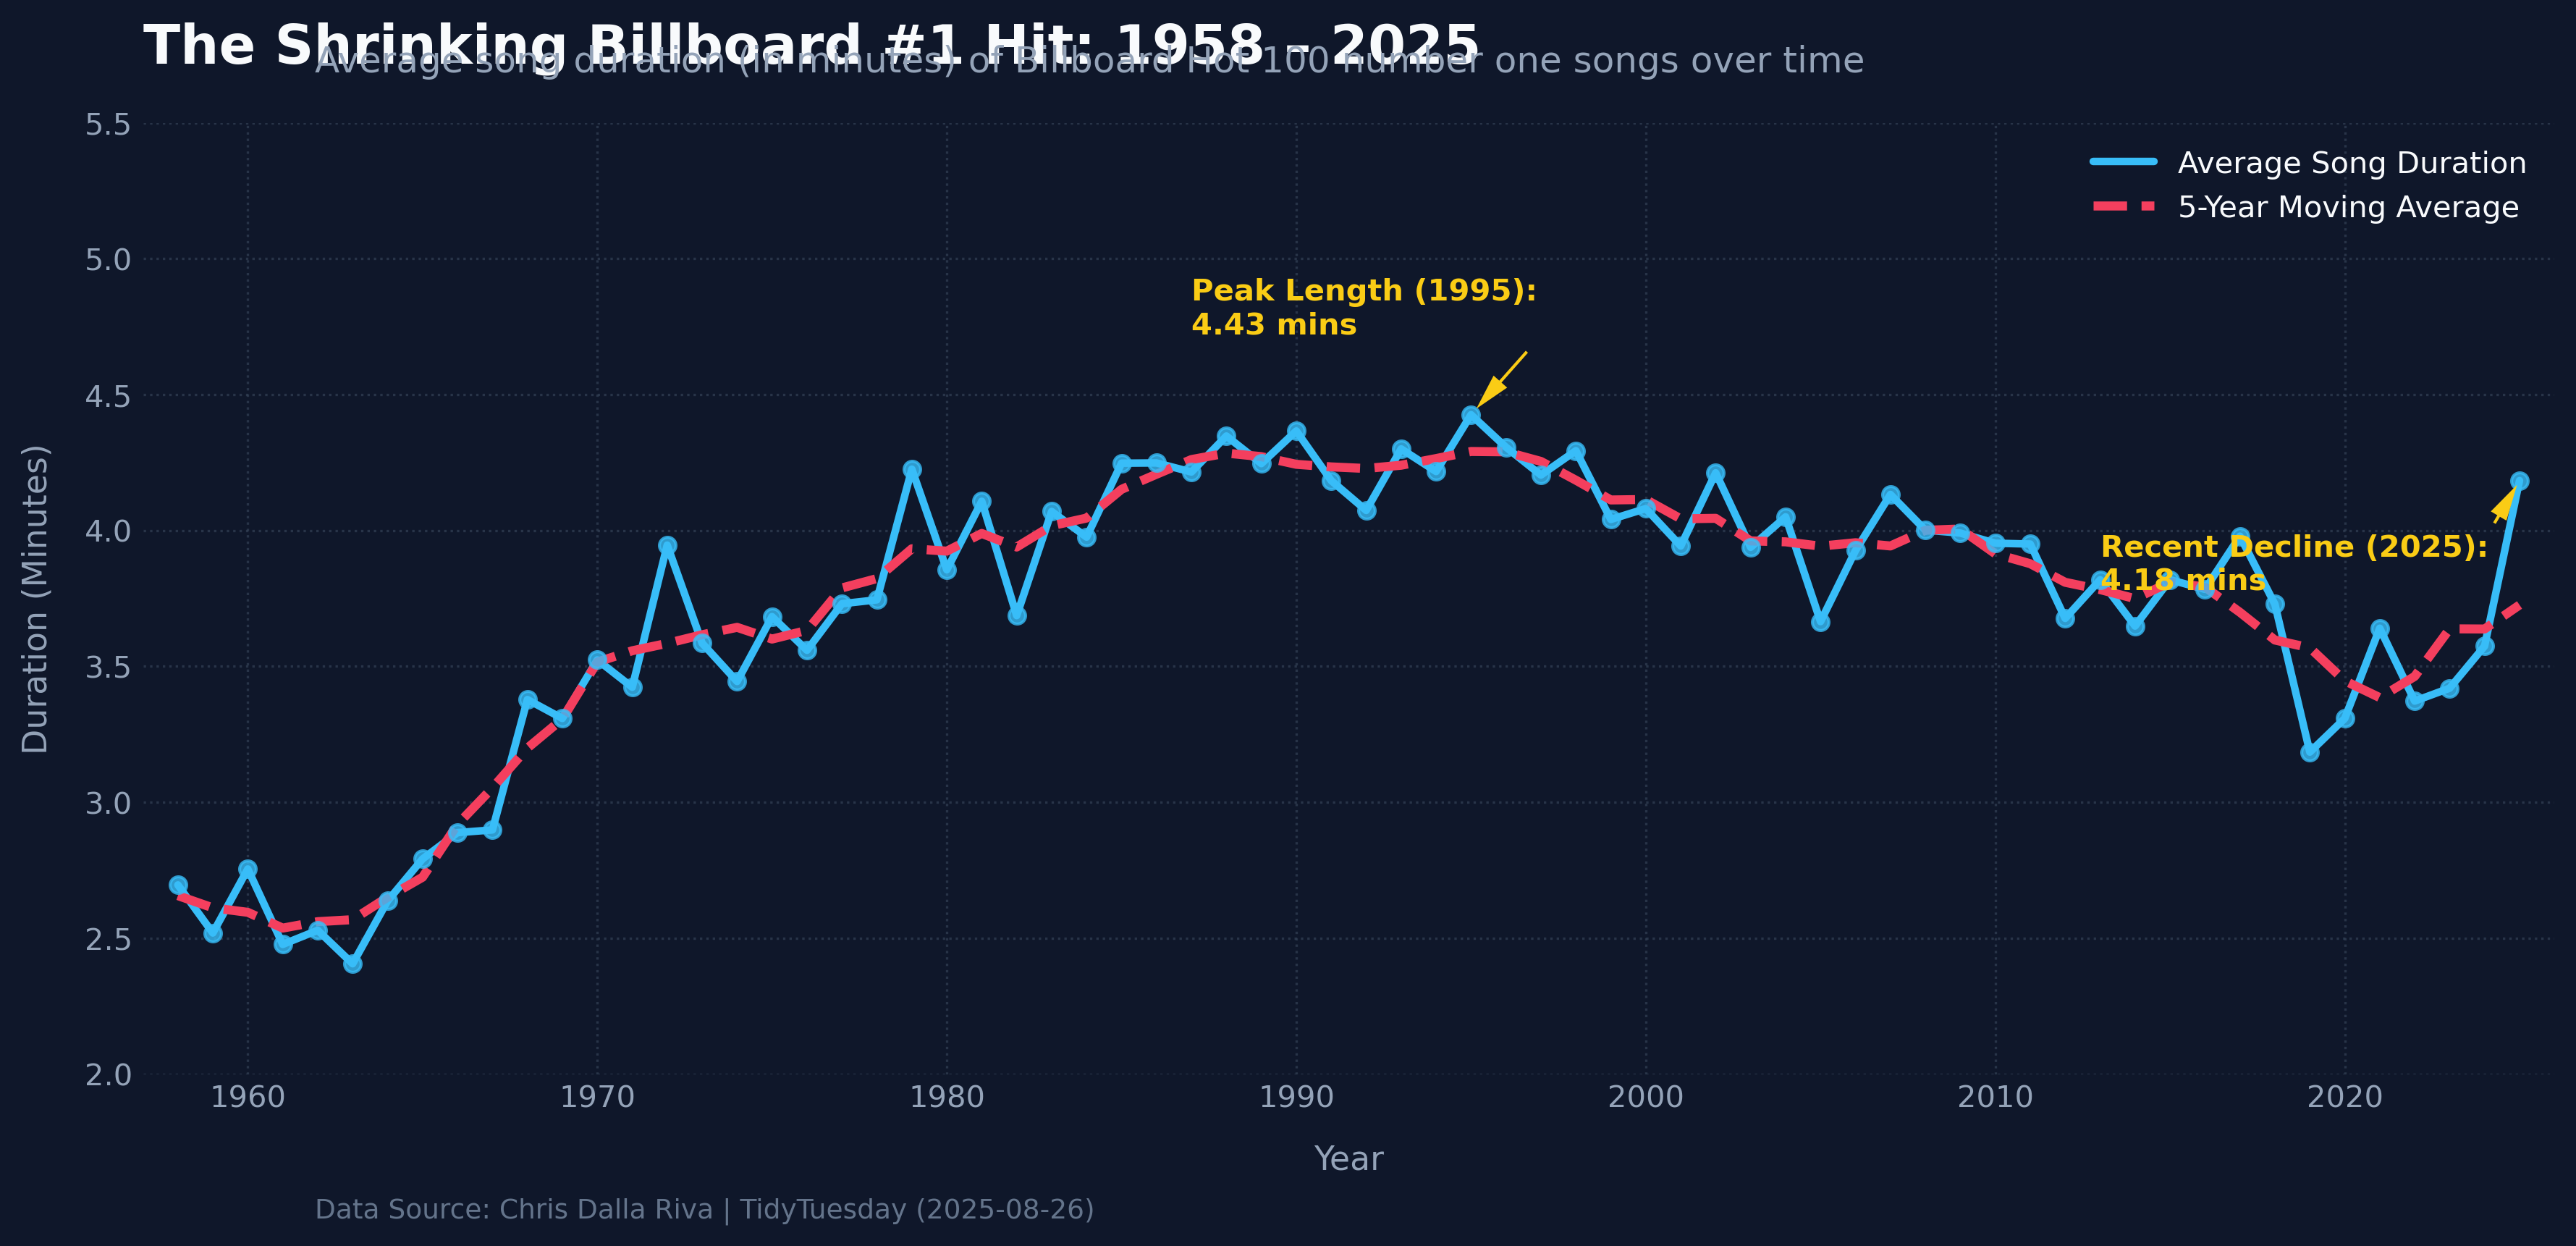

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# -----------------------------------------------------------------------------
# 1. Load Data directly from TidyTuesday GitHub repository
# -----------------------------------------------------------------------------
url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2025/2025-08-26/billboard.csv"
billboard = pd.read_csv(url)

# -----------------------------------------------------------------------------
# 2. Data Cleaning & Preparation
# -----------------------------------------------------------------------------
# Convert date column to datetime
billboard["date"] = pd.to_datetime(billboard["date"])

# Extract Year & Decade
billboard["year"] = billboard["date"].dt.year
billboard["decade"] = (billboard["year"] // 10 * 10).astype(str) + "s"

# Filter out rows missing song length
df_length = billboard.dropna(subset=["length_sec"]).copy()

# Calculate average song duration per year
yearly_avg = (
    df_length.groupby("year")["length_sec"].mean().reset_index()
)
yearly_avg["minutes"] = yearly_avg["length_sec"] / 60

# -----------------------------------------------------------------------------
# 3. Styling Configuration
# -----------------------------------------------------------------------------
plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(12, 6), dpi=300)

# Set background & font aesthetics
fig.patch.set_facecolor("#0F172A")  # Dark slate background
ax.set_facecolor("#0F172A")

# Plot trendline
ax.plot(
    yearly_avg["year"],
    yearly_avg["minutes"],
    color="#38BDF8",
    linewidth=2.5,
    label="Average Song Duration",
)

# Smooth Trend curve (Rolling 5-year average)
yearly_avg["smooth"] = (
    yearly_avg["minutes"].rolling(window=5, min_periods=1, center=True).mean()
)
ax.plot(
    yearly_avg["year"],
    yearly_avg["smooth"],
    color="#F43F5E",
    linewidth=3,
    linestyle="--",
    label="5-Year Moving Average",
)

# Scatter points for individual years
ax.scatter(
    yearly_avg["year"],
    yearly_avg["minutes"],
    color="#38BDF8",
    s=30,
    alpha=0.8,
    zorder=3,
)

# -----------------------------------------------------------------------------
# 4. Annotations & Insights
# -----------------------------------------------------------------------------
# Peak year annotation
peak_year = yearly_avg.loc[yearly_avg["minutes"].idxmax()]
ax.annotate(
    f"Peak Length ({int(peak_year['year'])}):\n{peak_year['minutes']:.2f} mins",
    xy=(peak_year["year"], peak_year["minutes"]),
    xytext=(peak_year["year"] - 8, peak_year["minutes"] + 0.3),
    arrowprops=dict(
        facecolor="#FACC15", edgecolor="none", shrink=0.08, width=1, headwidth=6
    ),
    color="#FACC15",
    fontsize=10,
    fontweight="bold",
)

# Recent drop annotation
latest_year = yearly_avg.iloc[-1]
ax.annotate(
    f"Recent Decline ({int(latest_year['year'])}):\n{latest_year['minutes']:.2f} mins",
    xy=(latest_year["year"], latest_year["minutes"]),
    xytext=(latest_year["year"] - 12, latest_year["minutes"] - 0.4),
    arrowprops=dict(
        facecolor="#FACC15", edgecolor="none", shrink=0.08, width=1, headwidth=6
    ),
    color="#FACC15",
    fontsize=10,
    fontweight="bold",
)

# -----------------------------------------------------------------------------
# 5. Chart Titles & Axis Labels
# -----------------------------------------------------------------------------
plt.title(
    "The Shrinking Billboard #1 Hit: 1958 – 2025",
    fontsize=18,
    fontweight="bold",
    color="#F8FAFC",
    pad=20,
    loc="left",
)

plt.suptitle(
    "Average song duration (in minutes) of Billboard Hot 100 number one songs over time",
    fontsize=12,
    color="#94A3B8",
    x=0.125,
    y=0.91,
    ha="left",
)

ax.set_xlabel("Year", fontsize=11, color="#94A3B8", labelpad=10)
ax.set_ylabel("Duration (Minutes)", fontsize=11, color="#94A3B8", labelpad=10)

# Grid & Spines customization
ax.grid(color="#334155", linestyle=":", linewidth=0.8, alpha=0.7)
for spine in ax.spines.values():
    spine.set_visible(False)

# Tick formatting
ax.tick_params(colors="#94A3B8", labelsize=10)
ax.set_xlim(1957, 2026)
ax.set_ylim(2.0, 5.5)

# Legend
legend = ax.legend(
    facecolor="#1E293B", edgecolor="none", labelcolor="#F8FAFC", fontsize=10
)

# Caption / Credit
fig.text(
    0.125,
    0.01,
    "Data Source: Chris Dalla Riva | TidyTuesday (2025-08-26)",
    fontsize=9,
    color="#64748B",
)

plt.tight_layout()
plt.subplots_adjust(top=0.85, bottom=0.12)
plt.show()